# Лабораторная работа 1

Задача: даны два отсортированных массива целых чисел длины M и N. Надо вернуть True, если у них есть хотя бы один общий элемент, иначе False.

Примеры:
- [1,2,3], [3,4,5] -> True
- [2,4,6], [3,5,7] -> False
- [], [] -> False

Цель: написать 4 решения и выяснить, какой алгоритм быстрее при каких размерах массивов.

| Алгоритм | Время | Память |
|---|---|---|
| Два указателя | O(M+N) | O(1) |
| Бинарный поиск | O(M log N) | O(1) |
| Экспоненциальный поиск | O(M log(2N/M)) | O(1) |
| Двойной бинарный поиск | O(M log(2N/M)) | O(log M) |

In [1]:
import time
import random
import os

import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

## Алгоритмы

### 1. Два указателя
Ставим указатели в начало обоих массивов. Если элементы равны, ответ True, иначе двигаем тот указатель, где элемент меньше.

In [2]:
def two_pointers(a, b):
    i = 0
    j = 0
    while i < len(a) and j < len(b):
        if a[i] == b[j]:
            return True
        elif a[i] < b[j]:
            i += 1
        else:
            j += 1
    return False

In [3]:
print(two_pointers([1, 2, 3], [3, 4, 5]))
print(two_pointers([2, 4, 6], [3, 5, 7]))
print(two_pointers([], []))

True
False
False


### 2. Бинарный поиск
Для каждого элемента a делаем обычный бинарный поиск в b.

In [4]:
def binary_search(a, b):
    for x in a:
        left = 0
        right = len(b) - 1
        while left <= right:
            mid = (left + right) // 2
            if b[mid] == x:
                return True
            elif b[mid] < x:
                left = mid + 1
            else:
                right = mid - 1
    return False

In [5]:
print(binary_search([1, 2, 3], [3, 4, 5]))
print(binary_search([2, 4, 6], [3, 5, 7]))
print(binary_search([], []))

True
False
False


### 3. Экспоненциальный поиск
Идём по массиву a. Для каждого x в массиве b прыгаем от текущей позиции на 1, 2, 4, 8... пока не перепрыгнем x. Потом в найденном куске делаем бинарный поиск.
Следующий элемент ищем уже с того места, где остановились, потому что он больше.

In [6]:
def exponential_search(a, b):
    n = len(b)
    start = 0
    for x in a:
        step = 1
        while start + step < n and b[start + step] < x:
            step *= 2

        left = start + step // 2
        right = start + step
        if right > n - 1:
            right = n - 1
        while left <= right:
            mid = (left + right) // 2
            if b[mid] == x:
                return True
            elif b[mid] < x:
                left = mid + 1
            else:
                right = mid - 1

        start = left
    return False

In [7]:
print(exponential_search([1, 2, 3], [3, 4, 5]))
print(exponential_search([2, 4, 6], [3, 5, 7]))
print(exponential_search([], []))

True
False
False


### 4. Двойной бинарный поиск
Берём средний элемент a и бинарным поиском находим, куда он встал бы в b. Тогда левую половину a надо искать только слева от этого места, а правую только справа. Дальше то же самое рекурсивно для каждой половины.

In [8]:
def search_part(a, a_left, a_right, b, b_left, b_right):
    if a_left > a_right or b_left > b_right:
        return False

    mid = (a_left + a_right) // 2
    x = a[mid]

    left = b_left
    right = b_right
    while left <= right:
        m = (left + right) // 2
        if b[m] == x:
            return True
        elif b[m] < x:
            left = m + 1
        else:
            right = m - 1

    if search_part(a, a_left, mid - 1, b, b_left, left - 1):
        return True
    return search_part(a, mid + 1, a_right, b, left, b_right)


def double_binary(a, b):
    return search_part(a, 0, len(a) - 1, b, 0, len(b) - 1)

In [9]:
print(double_binary([1, 2, 3], [3, 4, 5]))
print(double_binary([2, 4, 6], [3, 5, 7]))
print(double_binary([], []))

True
False
False


In [10]:
algorithms = {
    "two_pointers": two_pointers,
    "binary_search": binary_search,
    "exponential_search": exponential_search,
    "double_binary": double_binary,
}

## Проверка

Сначала примеры из условия и разные крайние случаи. Каждый тест запускаю в двух порядках, f(a, b) и f(b, a).

In [11]:
tests = [
    ([1, 2, 3], [3, 4, 5], True),
    ([2, 4, 6], [3, 5, 7], False),
    ([], [], False),
    ([], [1, 2], False),
    ([5], [5], True),
    ([5], [6], False),
    ([1, 2, 3], [4, 5, 6], False),
    ([1, 1, 2], [2, 2, 3], True),
    ([-5, 0], [-5, 7], True),
    ([10], list(range(0, 100, 2)), True),
    ([11], list(range(0, 100, 2)), False),
]

for name in algorithms:
    f = algorithms[name]
    for a, b, answer in tests:
        if f(a, b) != answer or f(b, a) != answer:
            print("ошибка:", name, a, b)
print("готово")

готово


Потом случайные массивы. Правильный ответ считаю простым перебором (каждый с каждым), он медленный, но точно правильный.

In [12]:
def brute_force(a, b):
    for x in a:
        for y in b:
            if x == y:
                return True
    return False


errors = 0
for t in range(5000):
    a = sorted(random.randint(-100, 100) for _ in range(random.randint(0, 30)))
    b = sorted(random.randint(-100, 100) for _ in range(random.randint(0, 100)))
    answer = brute_force(a, b)
    for name in algorithms:
        if algorithms[name](a, b) != answer:
            errors += 1
            print("ошибка:", name, a, b)
print("ошибок:", errors)

ошибок: 0


## Замеры

Данные беру как советуют в задании: в массиве b нечётные числа 1, 3, 5, ..., 2N-1, в массиве a (он короче) чётные, равномерно раскиданные по тому же диапазону. Общих элементов нет, значит каждый алгоритм проходит до конца (худший случай).

Время меряю через time.perf_counter. Каждую функцию запускаю 7 раз, все 7 времён сохраняю в CSV, а для графиков и таблиц беру медиану, потому что она меньше зависит от случайных выбросов.

In [13]:
def make_arrays(m, n):
    b = list(range(1, 2 * n, 2))
    a = []
    for i in range(m):
        a.append(2 * ((2 * i + 1) * n // (2 * m)))
    return a, b

print(make_arrays(4, 16))

([4, 12, 20, 28], [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31])


In [14]:
def measure(f, a, b):
    times = []
    for _ in range(7):
        start = time.perf_counter()
        f(a, b)
        end = time.perf_counter()
        times.append(end - start)
    return times


def run(sizes, filename):
    rows = []
    for m, n in sizes:
        a, b = make_arrays(m, n)
        for name in algorithms:
            times = measure(algorithms[name], a, b)
            for k in range(7):
                rows.append([m, n, name, k + 1, times[k]])
    raw = pd.DataFrame(rows, columns=["M", "N", "algorithm", "repeat", "time"])
    raw.to_csv("results/" + filename, index=False)
    # для графиков и таблиц беру медиану из 7 запусков
    return raw.groupby(["M", "N", "algorithm"], as_index=False)["time"].median()


names = {
    "two_pointers": "Два указателя",
    "binary_search": "Бинарный поиск",
    "exponential_search": "Экспоненциальный",
    "double_binary": "Двойной бинарный",
}
markers = {
    "two_pointers": "o",
    "binary_search": "s",
    "exponential_search": "^",
    "double_binary": "D",
}
colors = {
    "two_pointers": "tab:blue",
    "binary_search": "tab:orange",
    "exponential_search": "tab:green",
    "double_binary": "tab:red",
}


def plot(df, x, xlabel, title, filename):
    plt.figure(figsize=(9, 5))
    for name in algorithms:
        d = df[df["algorithm"] == name]
        plt.plot(d[x], d["time"], marker=markers[name], color=colors[name], label=names[name])
    plt.xscale("log", base=2)
    plt.yscale("log")
    plt.xlabel(xlabel)
    plt.ylabel("время, с")
    plt.title(title)
    plt.grid(alpha=0.4)
    plt.legend()
    plt.savefig("results/" + filename)
    plt.show()

## Эксперимент 1. M = N

Размеры от 2^4 до 2^17.

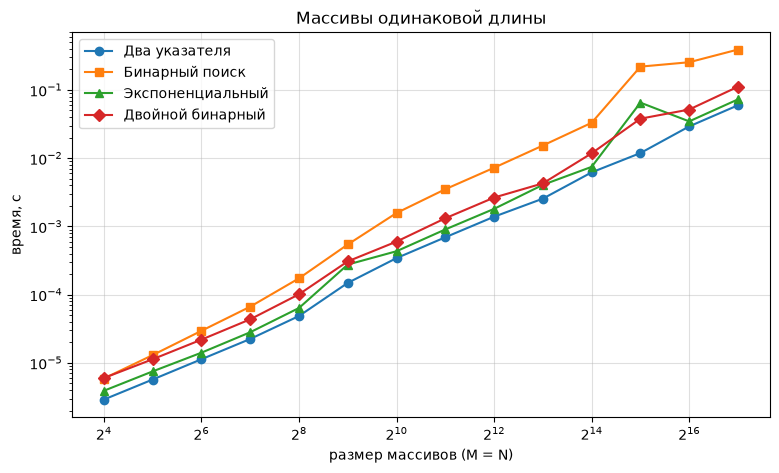

In [15]:
exp1 = run([(2 ** k, 2 ** k) for k in range(4, 18)], "exp1.csv")
plot(exp1, "N", "размер массивов (M = N)", "Массивы одинаковой длины", "exp1.png")

In [16]:
# время в миллисекундах
t1 = exp1.pivot(index="N", columns="algorithm", values="time") * 1000
t1.round(3)

algorithm,binary_search,double_binary,exponential_search,two_pointers
N,,,,
16,0.006,0.006,0.004,0.003
32,0.013,0.011,0.007,0.006
64,0.029,0.022,0.014,0.011
128,0.067,0.044,0.028,0.022
256,0.173,0.101,0.064,0.049
512,0.543,0.307,0.276,0.149
1024,1.572,0.599,0.433,0.343
2048,3.508,1.316,0.902,0.693
4096,7.241,2.647,1.808,1.387


Тут два указателя оказались самыми быстрыми на всех размерах. На самом большом размере (N = 2^17) они отработали примерно за 60 мс, экспоненциальный за ~73 мс, двойной бинарный за ~110 мс, а бинарный поиск почти за 400 мс, то есть в 6.5 раз медленнее.
Чем больше N, тем сильнее бинарный отстаёт (на N = 16 было всего в 2 раза), это как раз лишний log N в сложности. На 2^15 у бинарного и экспоненциального какой-то скачок, думаю, компьютер в этот момент был чем-то занят.

## Эксперимент 2. N фиксированное, M меняется

N = 2^18, M от 1 до 2^18.

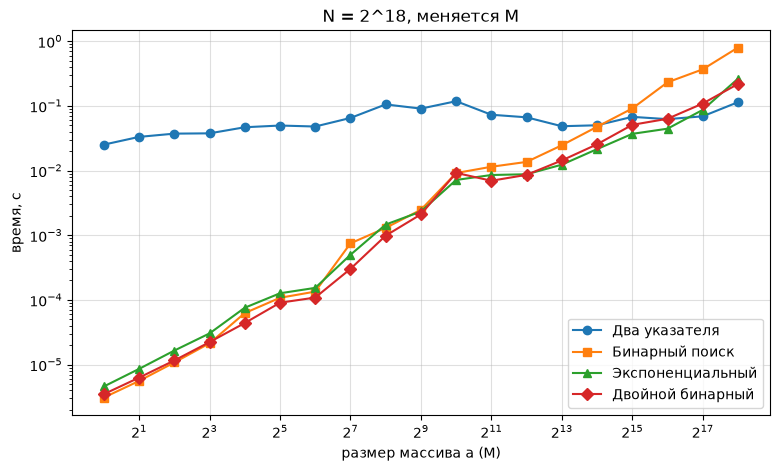

In [17]:
N = 2 ** 18
exp2 = run([(2 ** k, N) for k in range(0, 19)], "exp2.csv")
plot(exp2, "M", "размер массива a (M)", "N = 2^18, меняется M", "exp2.png")

In [18]:
t2 = exp2.pivot(index="M", columns="algorithm", values="time") * 1000
t2["fastest"] = t2.idxmin(axis=1)
t2.round(3)

algorithm,binary_search,double_binary,exponential_search,two_pointers,fastest
M,,,,,
1,0.003,0.003,0.005,25.159,binary_search
2,0.006,0.006,0.009,33.144,binary_search
4,0.011,0.012,0.017,37.213,binary_search
8,0.021,0.022,0.030,37.593,binary_search
16,0.063,0.044,0.076,46.703,double_binary
32,0.108,0.091,0.127,49.641,double_binary
64,0.135,0.109,0.154,47.926,double_binary
128,0.749,0.302,0.499,65.002,double_binary
256,1.299,0.986,1.464,105.267,double_binary


Чтобы было нагляднее, посчитал, во сколько раз каждый алгоритм быстрее двух указателей. Выше пунктирной линии значит быстрее, ниже значит медленнее.

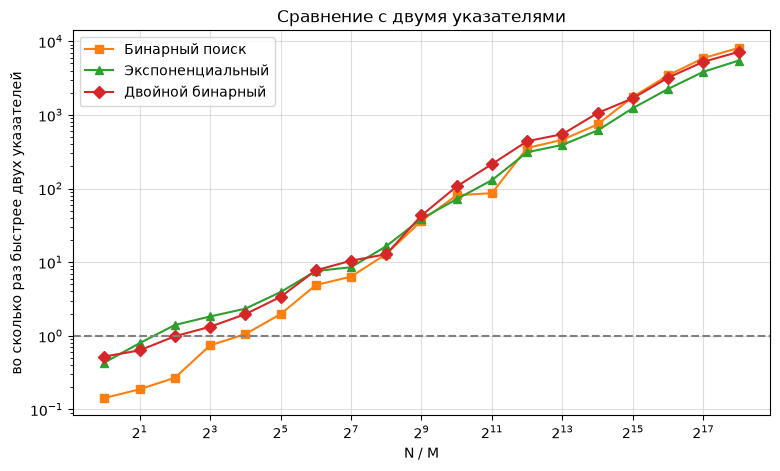

In [19]:
plt.figure(figsize=(9, 5))
for name in algorithms:
    if name == "two_pointers":
        continue
    plt.plot(N // t2.index, t2["two_pointers"] / t2[name], marker=markers[name], color=colors[name], label=names[name])
plt.axhline(1, color="gray", linestyle="--")
plt.xscale("log", base=2)
plt.yscale("log")
plt.xlabel("N / M")
plt.ylabel("во сколько раз быстрее двух указателей")
plt.title("Сравнение с двумя указателями")
plt.grid(alpha=0.4)
plt.legend()
plt.savefig("results/exp2_ratio.png")
plt.show()

Два указателя тут всё время работают примерно одинаково, 25-115 мс, потому что всё равно проходят весь b. А остальные при маленьком M работают за микросекунды: при M = 1 бинарный поиск отработал за 0.003 мс, это примерно в 8000 раз быстрее двух указателей.
При M до 8 чуть быстрее бинарный, дальше примерно до M = 4096 в основном двойной бинарный, но они почти одинаковые. Когда N/M от 4 до 32, лучше экспоненциальный. А два указателя снова выигрывают, только когда N/M = 1 или 2.
По второму графику видно, что бинарный поиск становится быстрее двух указателей примерно с N/M = 16, а экспоненциальный и двойной бинарный уже примерно с N/M = 4.

## Эксперимент 3. Разные M и N

Хочу проверить, важны сами размеры или только отношение N/M. Для каждой пары (M, N) смотрю, какой алгоритм самый быстрый.

In [20]:
sizes = [2 ** k for k in range(4, 17, 2)]
pairs = []
for m in sizes:
    for n in sizes:
        if m <= n:
            pairs.append((m, n))

exp3 = run(pairs, "exp3.csv")

table = {}
for m, n in pairs:
    d = exp3[(exp3["M"] == m) & (exp3["N"] == n)]
    fastest = d.loc[d["time"].idxmin(), "algorithm"]
    table.setdefault(m, {})[n] = fastest

pd.DataFrame(table).T.fillna("")

,16,64,256,1024,4096,16384,65536
16,exponential_search,exponential_search,exponential_search,double_binary,binary_search,binary_search,double_binary
64,,two_pointers,exponential_search,double_binary,double_binary,binary_search,double_binary
256,,,two_pointers,two_pointers,double_binary,double_binary,double_binary
1024,,,,exponential_search,exponential_search,exponential_search,exponential_search
4096,,,,,exponential_search,exponential_search,exponential_search
16384,,,,,,two_pointers,exponential_search
65536,,,,,,,two_pointers


Здесь картина не такая ровная, как во втором эксперименте: на маленьких размерах время совсем маленькое и замеры прыгают. Но в целом видно то же самое. При N/M = 1 побеждают два указателя или экспоненциальный (они там почти одинаковые), при N/M = 4 почти везде экспоненциальный, а при N/M от 64 и больше почти везде двойной бинарный или бинарный.
То есть важно не сколько элементов в массивах, а во сколько раз один массив больше другого.

## Выводы

Если массивы примерно одного размера, лучше всего два указателя. В первом эксперименте они были быстрее всех на всех размерах, а бинарный поиск на больших массивах проигрывал им в 6-7 раз.

Если один массив сильно меньше другого, то наоборот, два указателя самые медленные: при M = 1 почти в 8000 раз медленнее бинарного поиска. Тут лучше брать двойной бинарный или обычный бинарный, по времени они у меня почти не отличались.

Экспоненциальный поиск получился чем-то средним. Когда один массив больше другого примерно в 4-32 раза, он был самым быстрым, а в остальных случаях не сильно отставал от лучшего.

Ещё интересно, что у экспоненциального и двойного бинарного одинаковая сложность, но при M = N двойной бинарный был примерно в полтора раза медленнее экспоненциального. Думаю, это из-за рекурсии, в питоне вызов функции долгий. И памяти ему нужно O(log M) на рекурсию, а остальным O(1).